## ParFlow-CLM Single Column Run Comparisons 
This notebook loads and plots results from multiple single column ParFlow-CLM runs generated with the `PFCLM_SC_water_balance.ipynb` file.  Refer to ths notebook for additional details 


### 1.0 Importing packages

In [1]:
import os
import shutil
from pathlib import Path
from glob import glob


import matplotlib.pyplot as plt
import numpy as np
import netCDF4 as nc
import xarray as xr
import time as timer
import pandas as pd


import parflow as pf
from parflow import Run
from parflow.tools.fs import mkdir, cp, chdir, get_absolute_path, rm, exists
import parflow.tools.hydrology as hydro

## 2.0 Analysis
The next cell compares CLM output from multiple ParFlow-CLM runs. It shows grouped bars for the mean daily flux of each CLM variable and time-series lines for transpiration and infiltration. Add run folder names to `run_names` to include additional simulations. 

This is a good starting point for your homework. Feel free to modify to include more runs or plot other variables. 

/workspaces/ParFlow_CUAHSI_VU/Activity4_SingleColum_CLM/single_column_runs/Baseline_Col
  - qflx_tran_vegm
/workspaces/ParFlow_CUAHSI_VU/Activity4_SingleColum_CLM/single_column_runs/Forest_Col
  - qflx_tran_vegm


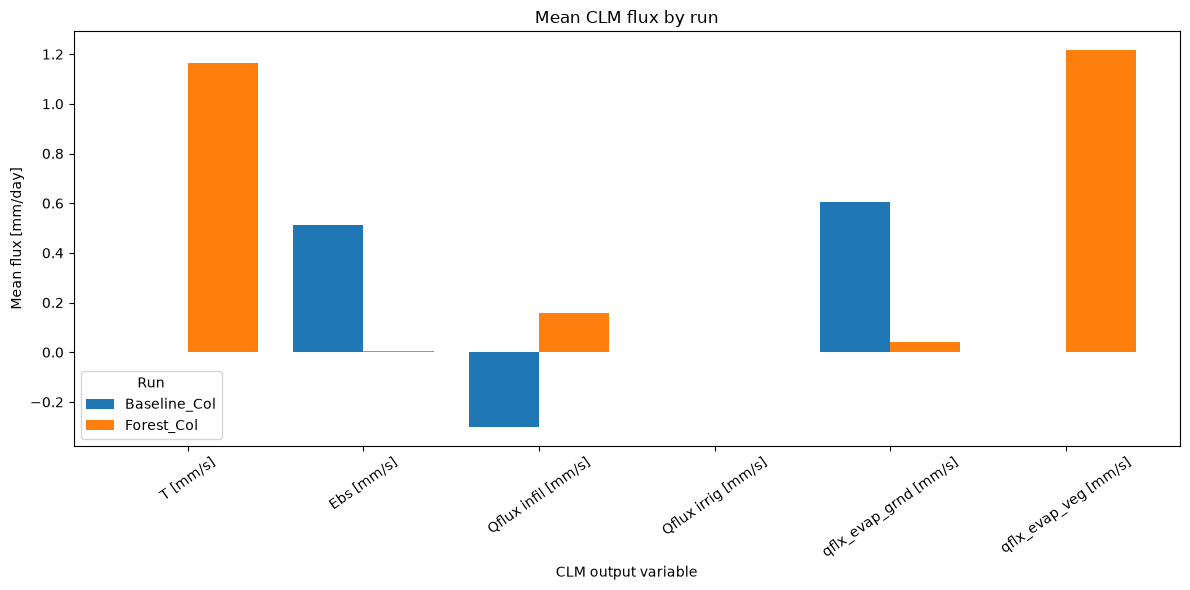

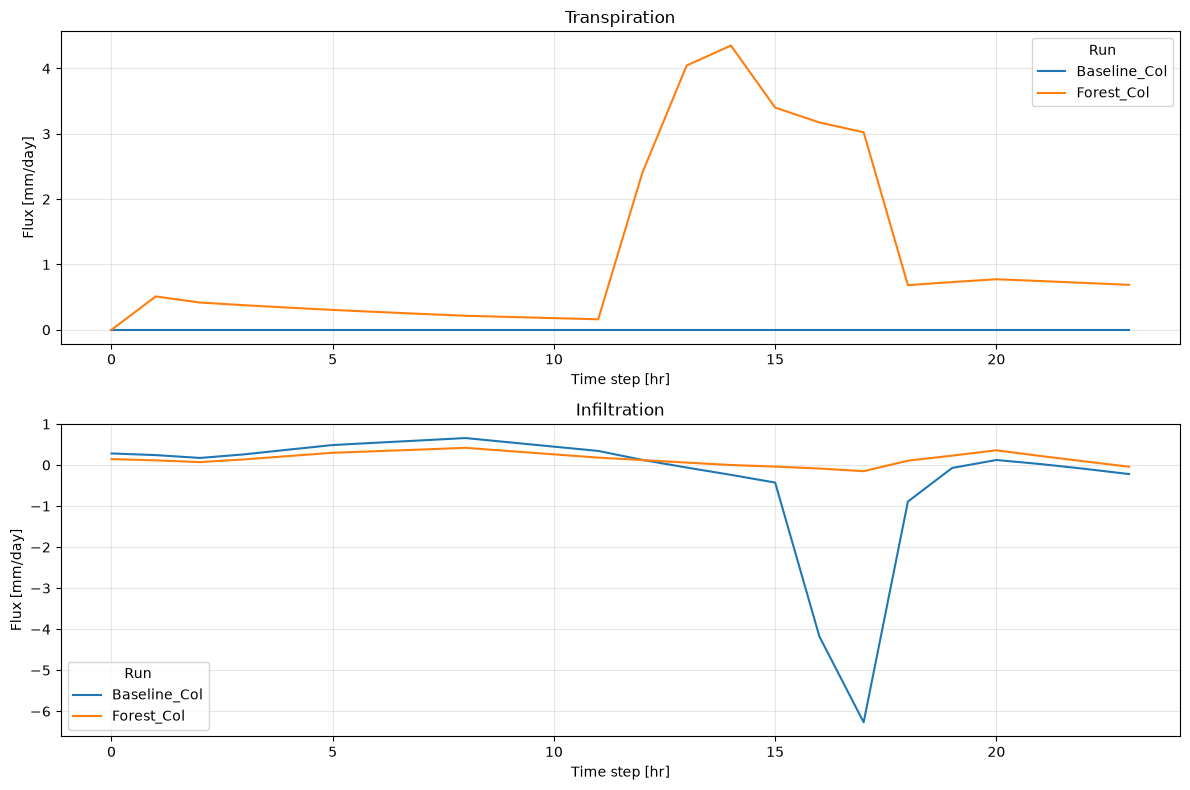

In [2]:
# Add the run names to compare (each run must have a matching folder and .pfidb file).
run_names = ["Baseline_Col", "Forest_Col"]
run_folder = "single_column_runs"

clm_variables = {
    "T [mm/s]": 8,
    "Ebs [mm/s]": 6,
    "Qflux infil [mm/s]": 9,
    "Qflux irrig [mm/s]": 12,
    "qflx_evap_grnd [mm/s]": 5,
    "qflx_evap_veg [mm/s]": 7,
}
clm_outputs = {}

for run_name in run_names:
    path = os.path.join(os.getcwd(), run_folder, run_name)
    print(path)

    run = Run.from_definition(os.path.join(path, f"{run_name}.pfidb"))

    clm_files = sorted(glob(os.path.join(path, f"{run_name}.out.clm_output.*.C.pfb")))
    if not clm_files:
        raise FileNotFoundError(f"No CLM output files found for run {run_name!r} in {path}")

    clm_data = pf.read_pfb_sequence(clm_files)
    clm_outputs[run_name] = pd.DataFrame(
        {name: clm_data[:, column, 0, 0] for name, column in clm_variables.items()}
    )

# Compare each run's mean CLM flux for every variable (converted from mm/s to mm/day).
mean_daily_flux = pd.DataFrame(
    {run_name: output.mean() * 3600 * 24 for run_name, output in clm_outputs.items()}
)
ax = mean_daily_flux.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_xlabel("CLM output variable")
ax.set_ylabel("Mean flux [mm/day]")
ax.set_title("Mean CLM flux by run")
ax.tick_params(axis="x", labelrotation=35)
ax.legend(title="Run")
plt.tight_layout()
plt.show()

# Plot hourly transpiration and infiltration series, with one line per run.
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for run_name, output in clm_outputs.items():
    hours = np.arange(len(output))
    axes[0].plot(hours, output["T [mm/s]"] * 3600 * 24, label=run_name)
    axes[1].plot(hours, output["Qflux infil [mm/s]"] * 3600 * 24, label=run_name)

axes[0].set_title("Transpiration")
axes[0].set_ylabel("Flux [mm/day]")
axes[0].set_xlabel("Time step [hr]")
axes[1].set_title("Infiltration")
axes[1].set_ylabel("Flux [mm/day]")
axes[1].set_xlabel("Time step [hr]")
for ax in axes:
    ax.legend(title="Run")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()